In [12]:
# Importing libraries
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# 1.0 Defining a function in Python

In [8]:
# f is a function
def f(x):
    return 3*x**2 - 4*x + 5

f(3.0)

20.0

Derivative:  14.000003002223593


(20.0, 14.000003002223593)

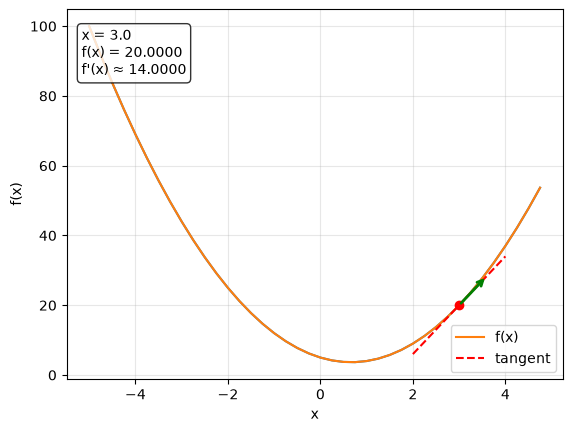

In [16]:
# Plot what this function `f` looks like in matplotlib
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

# Let's take a derivative of the slope
h = 0.000001
x = 3.0
print( 'Derivative: ', (f(x + h) - f(x))/h )

# adding the f(x) and derivative calculation to the text
from plot_derivative import plot_derivative

# Plot what this function `f` looks like, with the point and derivative direction
xs = np.arange(-5, 5, 0.25)
plot_derivative(f, x=3.0, xs=xs)


# 2.0 Adding a Data Structures to maintain these expressions


In [38]:
class Value:

    def __init__(self, data, _children=(), _op=''):
        self.data = data
        # we need to keep pointer to express the computational graphs
        self._prev = set(_children) # child is set for efficiency
        self._op = _op # remember what operation created the current value


    def __repr__(self):     # define how the print function operates on Value object. Try commenting it out and print Value(); shows <__main__.Value at 0x116b6ec00>
        return f"Value(data={self.data})"
    
    def __add__(self, other): # define what `+` operator does to the Value.data.
        out = Value(self.data + other.data, (self, other), '+') # we will return a new value object, and '+' here is the normal add operation.
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

a = Value(2.0)
b = Value(-3.0)
c = Value(10.0)
d = a*b + c #""" The direct call for: a*b + c would resemble (   a.__mul__(b)).__add__(c)    )"""
print(d) # Try print d._prev and d._op as well.


Value(data=4.0)


## 2.1 Visualize the function graph

In [ ]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.__prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg')

In [37]:
d._op

'+'